# Explore heuristic values for an empty maze

In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=4, suppress=True)

## Create the maze representation

Define an empty $10 \times 10$ maze and place the start and goal. The figures retain one-based coordinate labels, while the NumPy array uses zero-based indices.

In [2]:
n = 10
start = np.array([1, 1])
goal = np.array([8, 8])

maze = np.full((n, n), " ", dtype=str)
maze[tuple(start)] = "S"
maze[tuple(goal)] = "G"
maze

array([[' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ', ' '],
       [' ', 'S', ' ', ' ', ' ', ' ', ' ', ' ', ' ', ' '],
       [' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ', ' '],
       [' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ', ' '],
       [' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ', ' '],
       [' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ', ' '],
       [' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ', ' '],
       [' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ', ' '],
       [' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ', 'G', ' '],
       [' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ']], dtype='<U1')

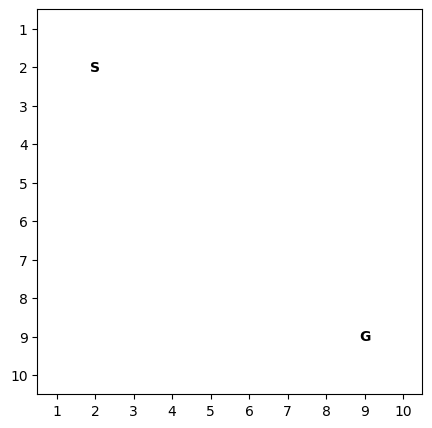

In [3]:
def show_values(values, cmap="YlOrRd_r", colorbar=True):
    """Display values on the maze and mark the start and goal."""
    figure, axis = plt.subplots(figsize=(6, 5))
    image = axis.imshow(values, cmap=cmap, origin="upper")
    axis.set_xticks(range(n), labels=range(1, n + 1))
    axis.set_yticks(range(n), labels=range(1, n + 1))
    axis.text(goal[1], goal[0], "G", ha="center", va="center", fontweight="bold")
    axis.text(start[1], start[0], "S", ha="center", va="center", fontweight="bold")
    if colorbar:
        figure.colorbar(image, ax=axis, label="value")
    plt.show()


show_values(np.zeros((n, n)), cmap="Greys", colorbar=False)

## Greedy Best-First Search: Use Manhattan Distance for $h(n)$

Manhattan distance is also called the $L_1$ norm. It is the difference in x values plus the difference in y values: $L_1(a,b) = |a_x-b_x| + |a_y-b_y|$.

Manhattan distance is a perfect heuristic for the maze: $h(n) = h^*(n)$ and $f(n) = f^*(n)$ (the asterisk represents the optimal value). Calculate $h(n)$.

[[16 15 14 13 12 11 10  9  8  9]
 [15 14 13 12 11 10  9  8  7  8]
 [14 13 12 11 10  9  8  7  6  7]
 [13 12 11 10  9  8  7  6  5  6]
 [12 11 10  9  8  7  6  5  4  5]
 [11 10  9  8  7  6  5  4  3  4]
 [10  9  8  7  6  5  4  3  2  3]
 [ 9  8  7  6  5  4  3  2  1  2]
 [ 8  7  6  5  4  3  2  1  0  1]
 [ 9  8  7  6  5  4  3  2  1  2]]


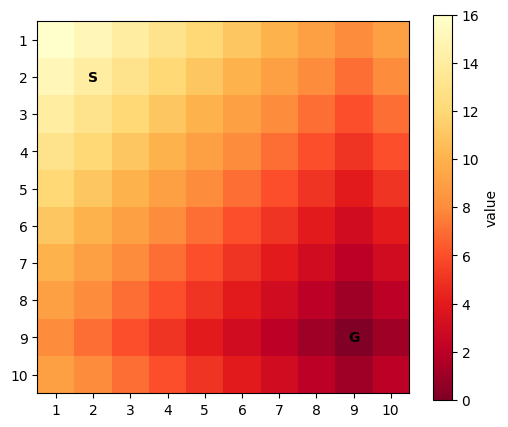

In [4]:
rows, columns = np.indices((n, n))
h_manhattan = np.abs(rows - goal[0]) + np.abs(columns - goal[1])
print(h_manhattan)
show_values(h_manhattan)

The algorithm will follow the color gradient from light yellow to dark red.

## A* with Manhattan heuristic

Calculate $f(n) = g(n) + h(n)$.

[[18 16 16 16 16 16 16 16 16 18]
 [16 14 14 14 14 14 14 14 14 16]
 [16 14 14 14 14 14 14 14 14 16]
 [16 14 14 14 14 14 14 14 14 16]
 [16 14 14 14 14 14 14 14 14 16]
 [16 14 14 14 14 14 14 14 14 16]
 [16 14 14 14 14 14 14 14 14 16]
 [16 14 14 14 14 14 14 14 14 16]
 [16 14 14 14 14 14 14 14 14 16]
 [18 16 16 16 16 16 16 16 16 18]]


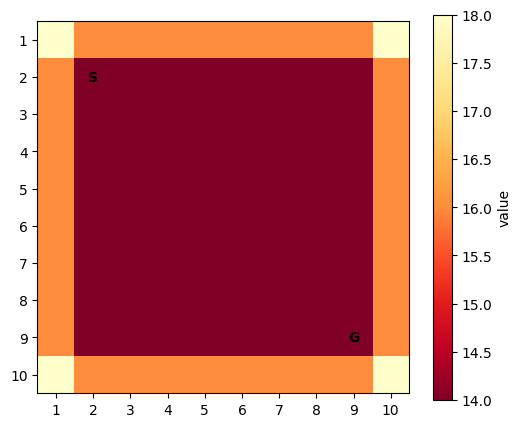

In [5]:
g = np.abs(rows - start[0]) + np.abs(columns - start[1])
f = g + h_manhattan
print(f)
show_values(f)

**Note:** In Manhattan geometry, all paths that go directly from $S$ to $G$ are optimal and have the same distance. Even with a perfect heuristic, the agent faces a plateau of positions with exactly the same $f(n) = C^*$. All directions are tied, so the tie-breaking strategy is important. For A* search with a reached data structure, this means that all states in the red square will be explored leading to very inefficient search!

[Amit Patel's discussion of heuristics](http://theory.stanford.edu/~amitp/GameProgramming/Heuristics.html) describes this and other issues and suggests increasing the value of $h(n)$ by a small factor, leading to weighted A* search.

## Weighted A* Search

Use $f(n) = g(n) + W \times h(n)$, with $W > 0$. For $W>1$, this is not guaranteed to be optimal because the weighted heuristic may become inadmissible, but it can reduce search time and memory. First, inflate the heuristic by 10%.

[[19.6 17.5 17.4 17.3 17.2 17.1 17.  16.9 16.8 18.9]
 [17.5 15.4 15.3 15.2 15.1 15.  14.9 14.8 14.7 16.8]
 [17.4 15.3 15.2 15.1 15.  14.9 14.8 14.7 14.6 16.7]
 [17.3 15.2 15.1 15.  14.9 14.8 14.7 14.6 14.5 16.6]
 [17.2 15.1 15.  14.9 14.8 14.7 14.6 14.5 14.4 16.5]
 [17.1 15.  14.9 14.8 14.7 14.6 14.5 14.4 14.3 16.4]
 [17.  14.9 14.8 14.7 14.6 14.5 14.4 14.3 14.2 16.3]
 [16.9 14.8 14.7 14.6 14.5 14.4 14.3 14.2 14.1 16.2]
 [16.8 14.7 14.6 14.5 14.4 14.3 14.2 14.1 14.  16.1]
 [18.9 16.8 16.7 16.6 16.5 16.4 16.3 16.2 16.1 18.2]]


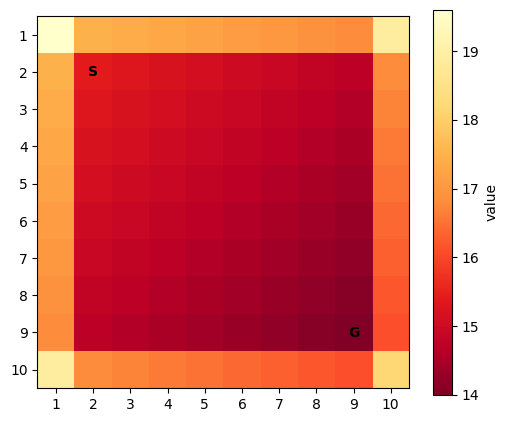

In [6]:
f = g + 1.10 * h_manhattan
print(f)
show_values(f)

The weighting create a slight gradient that leads directly from $S$ to $G$. Now try $W=5$. As $W$ increases, weighted A* approaches greedy best-first search (GBFS), which completely ignores $g(n)$.

[[82 76 72 68 64 60 56 52 48 54]
 [76 70 66 62 58 54 50 46 42 48]
 [72 66 62 58 54 50 46 42 38 44]
 [68 62 58 54 50 46 42 38 34 40]
 [64 58 54 50 46 42 38 34 30 36]
 [60 54 50 46 42 38 34 30 26 32]
 [56 50 46 42 38 34 30 26 22 28]
 [52 46 42 38 34 30 26 22 18 24]
 [48 42 38 34 30 26 22 18 14 20]
 [54 48 44 40 36 32 28 24 20 26]]


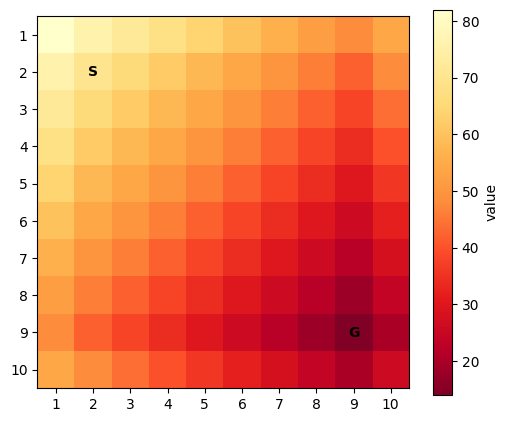

In [7]:
f = g + 5 * h_manhattan
print(f)
show_values(f)

Using $W<1$ makes the search behave more like uniform-cost search (BFS when every step has the same cost). This leads to exploring the area around $S$ first and very inefficient search.

[[10.   8.5  9.   9.5 10.  10.5 11.  11.5 12.  13.5]
 [ 8.5  7.   7.5  8.   8.5  9.   9.5 10.  10.5 12. ]
 [ 9.   7.5  8.   8.5  9.   9.5 10.  10.5 11.  12.5]
 [ 9.5  8.   8.5  9.   9.5 10.  10.5 11.  11.5 13. ]
 [10.   8.5  9.   9.5 10.  10.5 11.  11.5 12.  13.5]
 [10.5  9.   9.5 10.  10.5 11.  11.5 12.  12.5 14. ]
 [11.   9.5 10.  10.5 11.  11.5 12.  12.5 13.  14.5]
 [11.5 10.  10.5 11.  11.5 12.  12.5 13.  13.5 15. ]
 [12.  10.5 11.  11.5 12.  12.5 13.  13.5 14.  15.5]
 [13.5 12.  12.5 13.  13.5 14.  14.5 15.  15.5 17. ]]


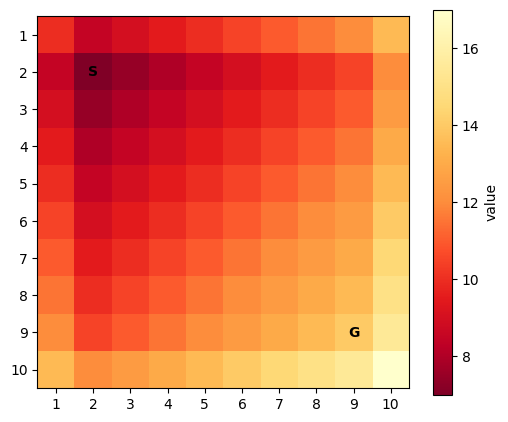

In [8]:
f = g + 0.5 * h_manhattan
print(f)
show_values(f)

## Greedy Best-First Search with Euclidean Distance for $h(n)$

Euclidean distance is the $L_2$ norm: $L_2(a,b) = \sqrt{(a_x-b_x)^2 + (a_y-b_y)^2}$. It is not perfect when the true cost follows Manhattan distance, but it is admissible: $h(n) \leq h^*(n)$.

[[11.3137 10.6301 10.      9.434   8.9443  8.544   8.2462  8.0623  8.
   8.0623]
 [10.6301  9.8995  9.2195  8.6023  8.0623  7.6158  7.2801  7.0711  7.
   7.0711]
 [10.      9.2195  8.4853  7.8102  7.2111  6.7082  6.3246  6.0828  6.
   6.0828]
 [ 9.434   8.6023  7.8102  7.0711  6.4031  5.831   5.3852  5.099   5.
   5.099 ]
 [ 8.9443  8.0623  7.2111  6.4031  5.6569  5.      4.4721  4.1231  4.
   4.1231]
 [ 8.544   7.6158  6.7082  5.831   5.      4.2426  3.6056  3.1623  3.
   3.1623]
 [ 8.2462  7.2801  6.3246  5.3852  4.4721  3.6056  2.8284  2.2361  2.
   2.2361]
 [ 8.0623  7.0711  6.0828  5.099   4.1231  3.1623  2.2361  1.4142  1.
   1.4142]
 [ 8.      7.      6.      5.      4.      3.      2.      1.      0.
   1.    ]
 [ 8.0623  7.0711  6.0828  5.099   4.1231  3.1623  2.2361  1.4142  1.
   1.4142]]


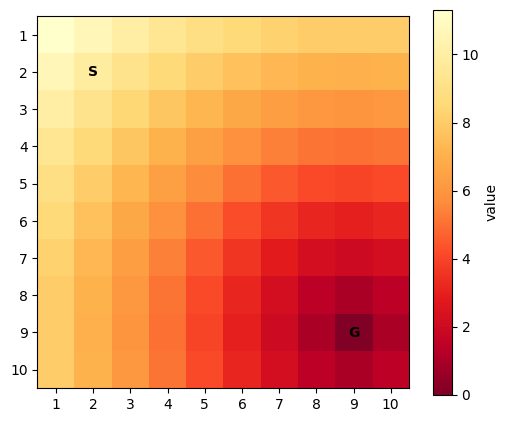

In [9]:
h_euclidean = np.hypot(rows - goal[0], columns - goal[1])
print(h_euclidean)
show_values(h_euclidean)

## A* with Euclidean Distance for $h(n)$

[[13.3137 11.6301 12.     12.434  12.9443 13.544  14.2462 15.0623 16.
  17.0623]
 [11.6301  9.8995 10.2195 10.6023 11.0623 11.6158 12.2801 13.0711 14.
  15.0711]
 [12.     10.2195 10.4853 10.8102 11.2111 11.7082 12.3246 13.0828 14.
  15.0828]
 [12.434  10.6023 10.8102 11.0711 11.4031 11.831  12.3852 13.099  14.
  15.099 ]
 [12.9443 11.0623 11.2111 11.4031 11.6569 12.     12.4721 13.1231 14.
  15.1231]
 [13.544  11.6158 11.7082 11.831  12.     12.2426 12.6056 13.1623 14.
  15.1623]
 [14.2462 12.2801 12.3246 12.3852 12.4721 12.6056 12.8284 13.2361 14.
  15.2361]
 [15.0623 13.0711 13.0828 13.099  13.1231 13.1623 13.2361 13.4142 14.
  15.4142]
 [16.     14.     14.     14.     14.     14.     14.     14.     14.
  16.    ]
 [17.0623 15.0711 15.0828 15.099  15.1231 15.1623 15.2361 15.4142 16.
  17.4142]]


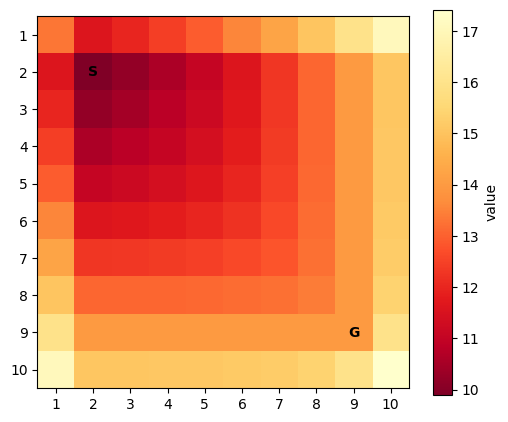

In [10]:
f = g + h_euclidean
print(f)
show_values(f)

**Note:** Euclidean and Manhattan geometry do not mix well here; the gradient is actually from the goal toward the start.
          A* expands every node with $f(n)<C^*$ and some nodes with $f(n)=C^*$. These nodes are shown in black below.

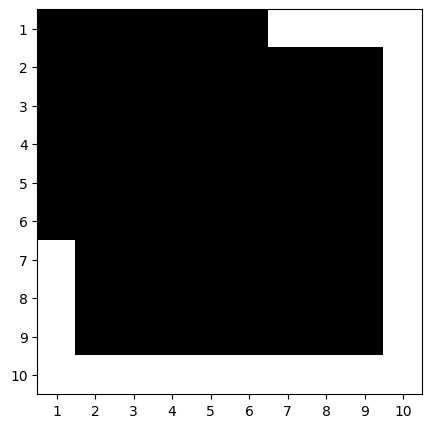

In [11]:
optimal_cost = f[tuple(goal)]
show_values(f <= optimal_cost, cmap="Greys", colorbar=False)

# Conclusion

We need to be careful when choosing heuristics to make sure that we still create a clear gradient for A* to follow. Otherwise, we will end up with an algorithm that is as inefficient as BFS. 

---
# BÀI 6 — ẢNH HƯỞNG CỦA HEURISTIC (PHẦN THỰC HÀNH BỔ SUNG)

**Yêu cầu:** Quan sát bản đồ $h(n)$ và $f(n)$ trong mê cung rỗng; so sánh Manhattan và Euclidean với GBFS và A*; giải thích lựa chọn heuristic phù hợp cho lưới 4 hướng; đề xuất một heuristic khác và xác định điều kiện tối ưu của A*.

**Quy ước:** Giữ nguyên mê cung rỗng $10\times10$ của notebook gốc, $S=(1,1)$, $G=(8,8)$ (tọa độ mảng Python bắt đầu từ 0). Hành động hợp lệ: lên, xuống, trái, phải; mỗi bước có chi phí 1. Bản đồ giá trị heuristic khác với quá trình chạy thuật toán tìm kiếm thực tế.

**Lưu ý về notebook gốc:** Cell tính `g = |r-r_S|+|c-c_S|` là chi phí ngắn nhất từ $S$ đến mọi ô **trong lưới rỗng**, không phải chi phí $g(n)$ dọc theo từng đường tìm kiếm khi có vật cản. Trong phần cài đặt thuật toán dưới đây, $g(n)$ được cập nhật từ đường đi thực tế.

## 6.1. Cơ sở lý thuyết: Manhattan, Euclidean và Chebyshev

Với vị trí $n=(r,c)$ và đích $G=(r_G,c_G)$:

- **Manhattan:** $h_M(n)=|r-r_G|+|c-c_G|$.
- **Euclidean:** $h_E(n)=\sqrt{(r-r_G)^2+(c-c_G)^2}$.
- **Chebyshev (đề xuất bổ sung):** $h_C(n)=\max(|r-r_G|,|c-c_G|)$.

Trên lưới 4 hướng, mỗi bước chi phí 1, luôn có $h_C(n)\le h_E(n)\le h_M(n)\le h^*(n)$, trong đó $h^*(n)$ là chi phí tối ưu còn lại. Trong mê cung rỗng, $h_M(n)=h^*(n)$; khi có tường, Manhattan vẫn là cận dưới của chi phí thực tế. Ba heuristic trên đều **admissible** (không ước lượng vượt quá chi phí tối ưu) và **consistent** (thỏa $h(n)\le 1+h(n')$ với các ô kề nhau).

GBFS ưu tiên $h(n)$ nhỏ nhất; A* ưu tiên $f(n)=g(n)+h(n)$. Sự khác nhau ở giá trị ưu tiên và cơ chế **tie-breaking** có thể ảnh hưởng đến số trạng thái được mở rộng.

In [12]:
# Chuẩn bị các bản đồ h(n), g*(n) và f(n) trên mê cung rỗng 10x10 của giảng viên
h_chebyshev = np.maximum(np.abs(rows - goal[0]), np.abs(columns - goal[1]))
g_optimal_empty = np.abs(rows - start[0]) + np.abs(columns - start[1])
h_maps = {
    "Manhattan": h_manhattan.astype(float),
    "Euclidean": h_euclidean.astype(float),
    "Chebyshev": h_chebyshev.astype(float),
}
f_maps = {name: g_optimal_empty + h for name, h in h_maps.items()}
assert np.all(h_chebyshev <= h_euclidean + 1e-10)
assert np.all(h_euclidean <= h_manhattan + 1e-10)
assert np.allclose(h_manhattan, np.abs(rows - goal[0]) + np.abs(columns - goal[1]))
print("Đã chuẩn bị các bản đồ heuristic và kiểm tra bất đẳng thức h_C ≤ h_E ≤ h_M.")

Đã chuẩn bị các bản đồ heuristic và kiểm tra bất đẳng thức h_C ≤ h_E ≤ h_M.


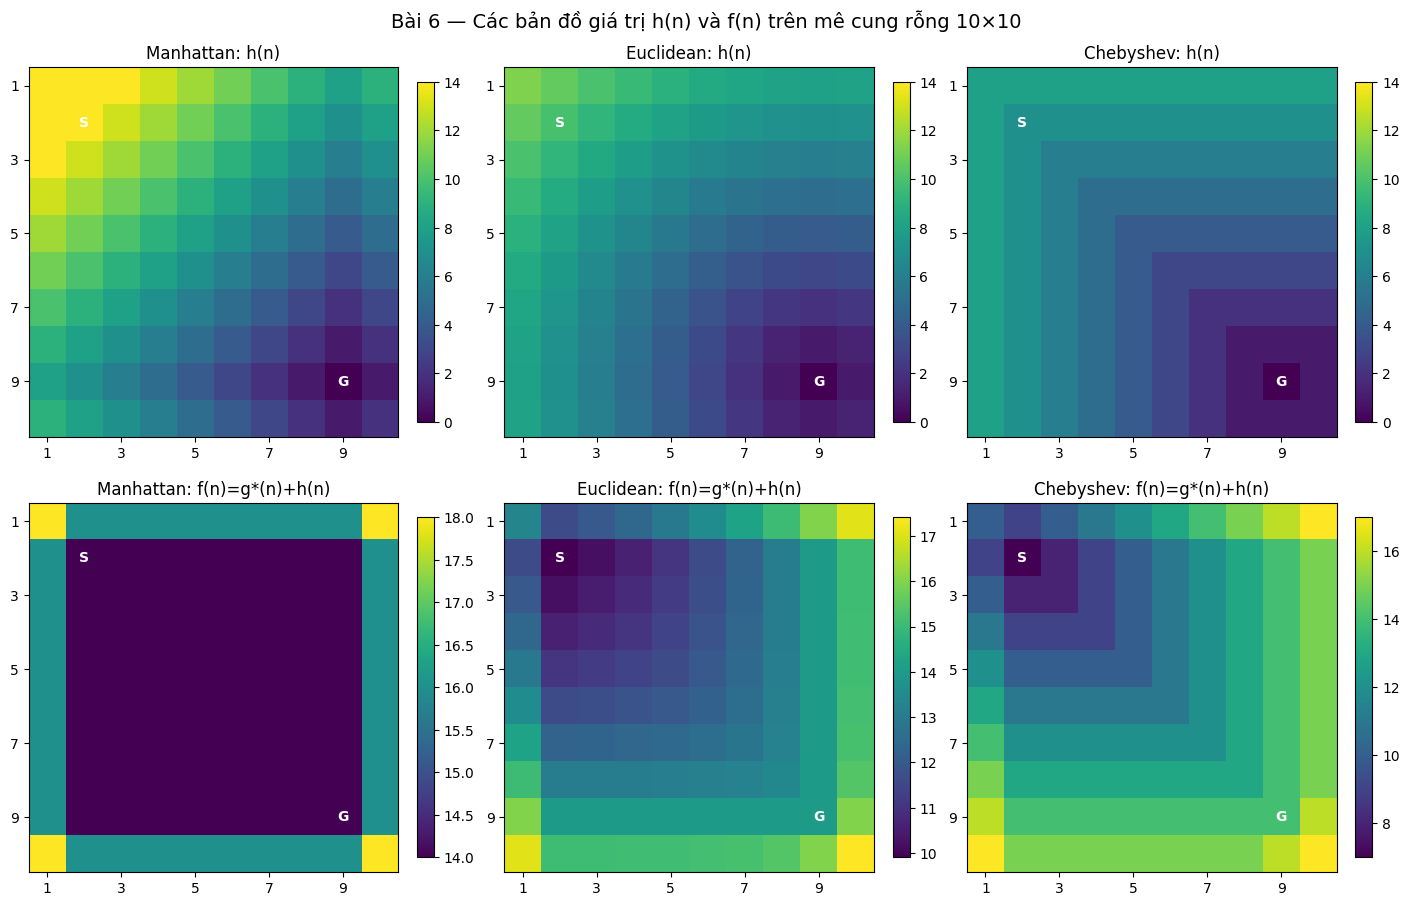

In [13]:
# Trực quan hóa cùng thang giá trị cho mỗi hàng, bảo đảm so sánh trực tiếp
fig, axes = plt.subplots(2, 3, figsize=(14, 9), constrained_layout=True)
for j, (name, hm) in enumerate(h_maps.items()):
    for i, (kind, vals) in enumerate((("h(n)", hm), ("f(n)=g*(n)+h(n)", f_maps[name]))):
        ax = axes[i, j]
        im = ax.imshow(vals, origin="upper", vmin=0 if i == 0 else None,
                       vmax=14 if i == 0 else None, cmap="viridis")
        ax.set_title(f"{name}: {kind}")
        ax.set_xticks(range(0, n, 2), labels=range(1, n + 1, 2))
        ax.set_yticks(range(0, n, 2), labels=range(1, n + 1, 2))
        ax.text(start[1], start[0], "S", ha="center", va="center", fontweight="bold", color="white")
        ax.text(goal[1], goal[0], "G", ha="center", va="center", fontweight="bold", color="white")
        fig.colorbar(im, ax=ax, fraction=0.046)
fig.suptitle("Bài 6 — Các bản đồ giá trị h(n) và f(n) trên mê cung rỗng 10×10", fontsize=14)
fig.savefig("hinh_bai6_heatmaps.png", dpi=150, bbox_inches="tight")
plt.show()

### Nhận xét bản đồ giá trị

1. **Manhattan ($h_M$):** Giá trị giảm đều theo số ô di chuyển bốn hướng đến đích. Trên mê cung rỗng, nó trùng chi phí tối ưu còn lại $h^*$. Với $f=g^*+h_M$, nhiều trạng thái nằm trong hình chữ nhật nối $S$ và $G$ có cùng giá trị $f=C^*=14$; điều này tạo ra *plateau*, do đó A* vẫn cần quy tắc xử lý hòa (*tie-breaking*).
2. **Euclidean ($h_E$):** Giá trị nhỏ hơn hoặc bằng Manhattan; cho biết khoảng cách đường thẳng. Vì di chuyển chéo không hợp lệ, nó thường đánh giá thấp hơn chi phí thực tế. Bản đồ $f=g^*+h_E$ khác dạng plateau của Manhattan, nhưng không vì thế mà luôn mở rộng ít hơn.
3. **Chebyshev ($h_C$):** Lấy độ lệch trục lớn nhất, cũng không vượt chi phí thực tế trên lưới bốn hướng nhưng kém thông tin hơn Manhattan.
4. **Quan trọng:** Hình bản đồ $f$ được tính với $g^*$ đã biết trước chỉ phục vụ minh họa lý thuyết. Khi chạy GBFS/A*, giá trị $g(n)$ là chi phí của đường đi được thuật toán khám phá, không được đọc trực tiếp từ bản đồ minh họa.

In [14]:
# Đối chiếu h(n) và f(n) tại một số tọa độ được chọn
import pandas as pd
sample_positions = [tuple(start), (4, 4), (1, 8), tuple(goal)]
comparison_rows = []
for position in sample_positions:
    r, col = position
    comparison_rows.append({
        "Position (0-based)": str(position),
        "g*(n)": int(g_optimal_empty[position]),
        "h_Manhattan": float(h_manhattan[position]),
        "h_Euclidean": round(float(h_euclidean[position]), 4),
        "h_Chebyshev": int(h_chebyshev[position]),
        "f_Manhattan": float(f_maps["Manhattan"][position]),
        "f_Euclidean": round(float(f_maps["Euclidean"][position]), 4),
    })
display(pd.DataFrame(comparison_rows))
print("C* =", int(h_manhattan[tuple(start)]), "bước (đường ngắn nhất từ S đến G).")
print("Số ô có f_M(n)=C* trong toàn lưới:", int(np.isclose(f_maps["Manhattan"], 14).sum()))

,Position (0-based),g*(n),h_Manhattan,h_Euclidean,h_Chebyshev,f_Manhattan,f_Euclidean
0,"(np.int64(1), np.int64(1))",0,14.0,9.8995,7,14.0,9.8995
1,"(4, 4)",6,8.0,5.6569,4,14.0,11.6569
2,"(1, 8)",7,7.0,7.0000,7,14.0,14.0000
3,"(np.int64(8), np.int64(8))",14,0.0,0.0000,0,14.0,14.0000


C* = 14 bước (đường ngắn nhất từ S đến G).
Số ô có f_M(n)=C* trong toàn lưới: 64


## 6.2. Thực nghiệm trực tiếp GBFS và A* trên mê cung rỗng

**Cài đặt bổ sung so với notebook gốc.** Để kết quả so sánh có thể tái lập, mỗi thuật toán được chạy độc lập trên cùng mê cung. Trong các hàng đợi ưu tiên, A* sử dụng khóa `(f, h, thứ_tự_đưa_vào)` để ưu tiên $h$ nhỏ khi cùng $f$; GBFS sử dụng `(h, thứ_tự_đưa_vào)`. Đây là lựa chọn tie-breaking cố định **cho thí nghiệm bổ sung**, không phải quy tắc duy nhất cho mọi triển khai.

**Quy ước thống kê:** `Nodes expanded` là số trạng thái lấy ra khỏi frontier rồi sinh các nút kế tiếp (không tính nút đích); `Max frontier` là số vị trí đang chờ xét lớn nhất (không tính bản sao heap lỗi thời). Tất cả thuật toán dùng kiểm tra trạng thái đã thăm thích hợp để không lặp vô hạn.

In [15]:
from collections import deque
from heapq import heappush, heappop
from itertools import count
from time import perf_counter

MOVES = ((-1, 0), (0, 1), (1, 0), (0, -1))  # Up, Right, Down, Left


def neighbors(grid, position):
    """Danh sách ô kề di chuyển được; 4 hướng, không đi qua 'X'."""
    r, c = position
    for dr, dc in MOVES:
        rr, cc = r + dr, c + dc
        if 0 <= rr < grid.shape[0] and 0 <= cc < grid.shape[1] and grid[rr, cc] != "X":
            yield (rr, cc)


def recover_path(parent, end):
    path = [end]
    while parent[path[-1]] is not None:
        path.append(parent[path[-1]])
    return path[::-1]


def heuristic_distance(pos, end, name):
    dr, dc = abs(pos[0]-end[0]), abs(pos[1]-end[1])
    if name == "Manhattan":
        return dr + dc
    if name == "Euclidean":
        return float(np.hypot(dr, dc))
    if name == "Chebyshev":
        return max(dr, dc)
    raise ValueError(f"Heuristic không hợp lệ: {name}")


def search_grid(grid, method="A*", heuristic="Manhattan"):
    """BFS, GBFS, A*; chi phí bước 1, heuristic admissible/consistent."""
    grid = np.asarray(grid)
    starts = np.argwhere(grid == "S")
    goals = np.argwhere(grid == "G")
    if len(starts) != 1 or len(goals) != 1:
        raise ValueError("Mỗi mê cung phải có đúng một S và một G.")
    begin, end = tuple(starts[0]), tuple(goals[0])
    parent = {begin: None}
    t0 = perf_counter()
    expanded = 0
    if method == "BFS":
        queue = deque([begin])
        seen = {begin}
        max_frontier = 1
        while queue:
            pos = queue.popleft()
            if pos == end:
                path = recover_path(parent, pos)
                return dict(method=method, heuristic="–", path=path, path_cost=len(path)-1,
                            expanded=expanded, max_frontier=max_frontier,
                            seconds=perf_counter()-t0)
            expanded += 1
            for neighbor in neighbors(grid, pos):
                if neighbor not in seen:
                    seen.add(neighbor)
                    parent[neighbor] = pos
                    queue.append(neighbor)
            max_frontier = max(max_frontier, len(queue))
    elif method in ("GBFS", "A*"):
        serial = count()
        heap = []
        open_g = {begin: 0}
        best_g = {begin: 0}
        processed_g = {}
        h0 = heuristic_distance(begin, end, heuristic)
        heappush(heap, ((h0, next(serial)) if method == "GBFS" else
                        (h0, h0, next(serial)), 0, begin))
        max_frontier = 1
        while heap:
            _, g_current, pos = heappop(heap)
            if open_g.get(pos) != g_current:
                continue  # bản ghi heap đã lỗi thời
            del open_g[pos]
            if processed_g.get(pos, float("inf")) <= g_current:
                continue
            processed_g[pos] = g_current
            if pos == end:
                path = recover_path(parent, pos)
                return dict(method=method, heuristic=heuristic, path=path,
                            path_cost=len(path)-1, expanded=expanded,
                            max_frontier=max_frontier, seconds=perf_counter()-t0)
            expanded += 1
            for neighbor in neighbors(grid, pos):
                proposed_g = g_current + 1
                if method == "GBFS" and neighbor in best_g:
                    continue  # GBFS: đánh dấu khi phát hiện lần đầu
                if method == "A*" and proposed_g >= best_g.get(neighbor, float("inf")):
                    continue
                best_g[neighbor] = proposed_g
                parent[neighbor] = pos
                h = heuristic_distance(neighbor, end, heuristic)
                priority = ((h, next(serial)) if method == "GBFS" else
                            (proposed_g + h, h, next(serial)))
                heappush(heap, (priority, proposed_g, neighbor))
                open_g[neighbor] = proposed_g
            max_frontier = max(max_frontier, len(open_g))
    else:
        raise ValueError("method phải thuộc BFS, GBFS hoặc A*.")
    return dict(method=method, heuristic=heuristic, path=None, path_cost=None,
                expanded=expanded, max_frontier=max_frontier, seconds=perf_counter()-t0)

# Kiểm tra trường hợp đơn giản + nghiệm tối ưu ở lưới rỗng
bfs_control = search_grid(maze, method="BFS")
assert bfs_control["path_cost"] == 14
assert bfs_control["path"][0] == tuple(start)
assert bfs_control["path"][-1] == tuple(goal)
print("Kiểm tra BFS: 14 bước — đạt.")

Kiểm tra BFS: 14 bước — đạt.


In [16]:
# So sánh hiệu suất trên mê cung rỗng 10x10
experimental_cases = [("BFS", "Manhattan")] + [
    (algo, heuristic)
    for algo in ("GBFS", "A*")
    for heuristic in ("Manhattan", "Euclidean", "Chebyshev")
]
results_empty = [search_grid(maze, method=algo, heuristic=heuristic)
                 for algo, heuristic in experimental_cases]
empty_table = pd.DataFrame([{
    "Algorithm": x["method"], "Heuristic": x["heuristic"],
    "Path cost": x["path_cost"], "Nodes expanded": x["expanded"],
    "Max frontier": x["max_frontier"]
} for x in results_empty])
display(empty_table)
assert all(x["path_cost"] == 14 for x in results_empty)
assert all(x["path"][0] == tuple(start) and x["path"][-1] == tuple(goal)
           for x in results_empty)
empty_table.to_csv("ket_qua_bai6_me_cung_rong.csv", index=False, encoding="utf-8-sig")
print("Đã lưu ket_qua_bai6_me_cung_rong.csv")

,Algorithm,Heuristic,Path cost,Nodes expanded,Max frontier
0,BFS,–,14,95,12
1,GBFS,Manhattan,14,14,29
2,GBFS,Euclidean,14,14,18
3,GBFS,Chebyshev,14,14,18
4,A*,Manhattan,14,14,29
5,A*,Euclidean,14,61,20
6,A*,Chebyshev,14,61,20


Đã lưu ket_qua_bai6_me_cung_rong.csv


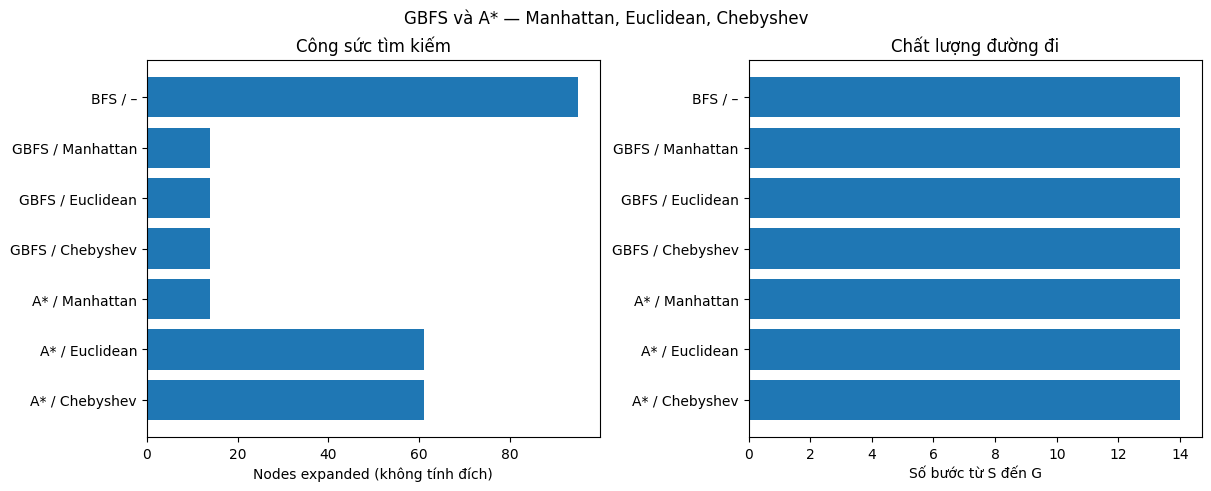

In [17]:
# Biểu đồ so sánh số trạng thái mở rộng và độ dài đường đi
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), constrained_layout=True)
names = [f"{row['Algorithm']} / {row['Heuristic']}" for _, row in empty_table.iterrows()]
axes[0].barh(names, empty_table["Nodes expanded"])
axes[0].set_xlabel("Nodes expanded (không tính đích)")
axes[0].set_title("Công sức tìm kiếm")
axes[0].invert_yaxis()
axes[1].barh(names, empty_table["Path cost"])
axes[1].set_xlabel("Số bước từ S đến G")
axes[1].set_title("Chất lượng đường đi")
axes[1].invert_yaxis()
fig.suptitle("GBFS và A* — Manhattan, Euclidean, Chebyshev")
fig.savefig("hinh_bai6_hieu_suat_me_cung_rong.png", dpi=150, bbox_inches="tight")
plt.show()

### Phân tích thí nghiệm lưới rỗng

- **GBFS** chỉ dựa vào $h(n)$, không tính chi phí đã đi. Trong mê cung rỗng này, cả GBFS-Manhattan và GBFS-Euclidean có thể tìm được một đường đi tối ưu; đây là kết quả **của thí nghiệm cụ thể**, không phải bảo đảm tối ưu tổng quát.
- **A*** xét $f(n)=g(n)+h(n)$ nên kết hợp thông tin chi phí đã đi và ước lượng chi phí còn lại. Với các heuristic nhất quán, cơ chế cập nhật chi phí được thực hiện đúng và chi phí cạnh không âm, A* graph search bảo đảm lời giải tối ưu.
- **Manhattan** là heuristic chính xác của lưới rỗng bốn hướng; **Euclidean/Chebyshev** là các cận dưới có thể nhỏ hơn chi phí tối ưu. Khi có nhiều trạng thái cùng $f(n)$, số nút được mở rộng còn chịu ảnh hưởng của tie-breaking. Vì vậy không nên suy ra "Manhattan luôn mở rộng ít nút hơn" từ một đồ thị đơn lẻ.

## 6.3. Kiểm tra bổ sung với mê cung có tường (nếu có `small_maze.txt`)

Mê cung rỗng chưa thể hiện rõ nhược điểm của GBFS vì không có vật cản khiến hướng đi tham lam bị sai lệch. Cell sau dùng lại **`small_maze.txt` từ Bài 2** nếu file có trong cùng thư mục; nếu không có, cell sẽ thông báo bỏ qua và notebook vẫn chạy bình thường. Đây là thí nghiệm mở rộng ngoài phạm vi minh họa lưới rỗng của notebook gốc.

In [18]:
from pathlib import Path
small_file = Path("small_maze.txt")
if small_file.exists():
    maze_lines = small_file.read_text(encoding="utf-8").splitlines()
    assert len({len(line) for line in maze_lines}) == 1, "Các dòng mê cung phải bằng độ rộng"
    maze_small = np.array([list(line) for line in maze_lines])
    results_small = [search_grid(maze_small, method=a, heuristic=h)
                     for a, h in experimental_cases]
    small_table = pd.DataFrame([{
        "Algorithm": x["method"], "Heuristic": x["heuristic"],
        "Path cost": x["path_cost"], "Nodes expanded": x["expanded"],
        "Max frontier": x["max_frontier"]
    } for x in results_small])
    display(small_table)
    assert all(x["path_cost"] == results_small[0]["path_cost"] for x in results_small
               if x["method"] == "A*")
    small_table.to_csv("ket_qua_bai6_small_maze.csv", index=False, encoding="utf-8-sig")
    print("Đã lưu ket_qua_bai6_small_maze.csv")
else:
    print("Không thấy small_maze.txt; bỏ qua thí nghiệm mở rộng có tường.")

,Algorithm,Heuristic,Path cost,Nodes expanded,Max frontier
0,BFS,–,19,92,9
1,GBFS,Manhattan,29,39,5
2,GBFS,Euclidean,29,39,5
3,GBFS,Chebyshev,29,54,4
4,A*,Manhattan,19,49,8
5,A*,Euclidean,19,56,7
6,A*,Chebyshev,19,56,6


Đã lưu ket_qua_bai6_small_maze.csv


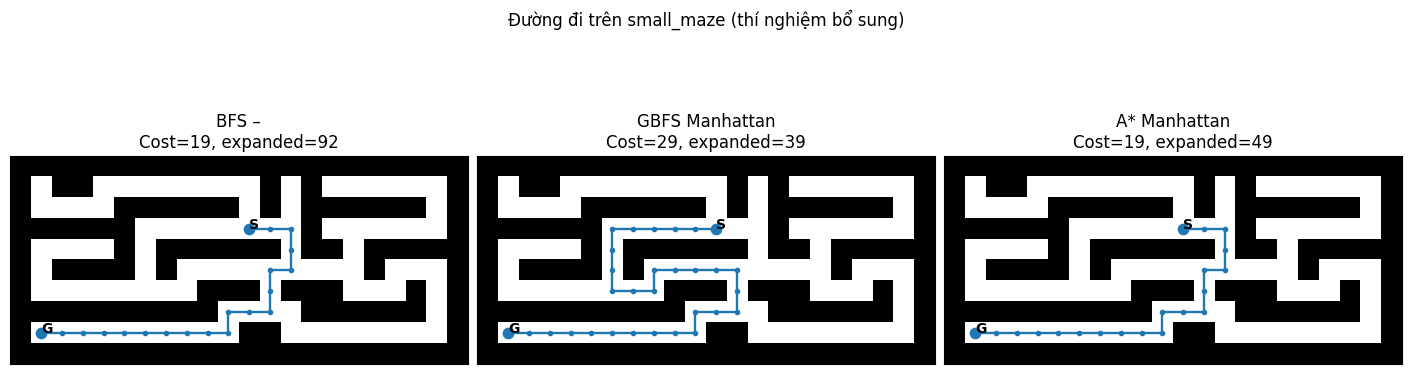

In [19]:
# Trực quan hóa lời giải BFS, GBFS-Manhattan, A*-Manhattan nếu có dữ liệu có tường
if small_file.exists():
    selected = [
        results_small[0],
        next(x for x in results_small if x["method"] == "GBFS" and x["heuristic"] == "Manhattan"),
        next(x for x in results_small if x["method"] == "A*" and x["heuristic"] == "Manhattan"),
    ]
    fig, axes = plt.subplots(1, 3, figsize=(14, 4.8), constrained_layout=True)
    wall_map = maze_small == "X"
    for ax, x in zip(axes, selected):
        ax.imshow(wall_map, cmap="Greys", origin="upper")
        if x["path"] is not None:
            pr, pc = zip(*x["path"])
            ax.plot(pc, pr, marker=".", linewidth=1.7)
            ax.scatter([pc[0], pc[-1]], [pr[0], pr[-1]], s=55)
            ax.text(pc[0], pr[0], "S", fontsize=10, fontweight="bold")
            ax.text(pc[-1], pr[-1], "G", fontsize=10, fontweight="bold")
        ax.set_title(f"{x['method']} {x['heuristic']}\n"
                     f"Cost={x['path_cost']}, expanded={x['expanded']}")
        ax.set_xticks([])
        ax.set_yticks([])
    fig.suptitle("Đường đi trên small_maze (thí nghiệm bổ sung)")
    fig.savefig("hinh_bai6_duong_di_small.png", dpi=150, bbox_inches="tight")
    plt.show()

## 6.4. Vì sao Manhattan phù hợp hơn Euclidean cho lưới 4 hướng?

Để di chuyển từ $n$ đến $G$, tác tử phải thay đổi tọa độ hàng ít nhất $\Delta r=|r-r_G|$ bước và tọa độ cột ít nhất $\Delta c=|c-c_G|$ bước. Vì **mỗi hành động chỉ thay đổi một tọa độ**, tổng số bước tối thiểu không thể nhỏ hơn $\Delta r+\Delta c$; đây chính là khoảng cách Manhattan.

Ngược lại, khoảng cách Euclidean đo đường thẳng nối hai vị trí, tương đương có thể dịch chuyển trên đường chéo trong không gian liên tục. Trong môi trường không cho phép đi chéo, nó thường đánh giá thấp số bước cần thiết. Khi có tường, đường thật có thể dài hơn Manhattan; tuy nhiên Manhattan vẫn không vượt chi phí tối ưu trong điều kiện mỗi bước 4 hướng có chi phí 1. Do đó, $h_M$ **dominates** $h_E$ (cận dưới chặt hơn ở mỗi trạng thái), mặc dù số nút mở rộng thực tế có thể bị chi phối bởi tie-breaking.

## 6.5. Heuristic khác: Chebyshev và điều kiện tối ưu của A*

**Đề xuất:** $h_C(n)=\max(|r-r_G|,|c-c_G|)$.

**Chứng minh admissible:** Với $a,b\ge0$, ta có $\max(a,b)\le a+b$. Vì $h_M(n)\le h^*(n)$ trên lưới bốn hướng, suy ra $h_C(n)\le h^*(n)$. Như vậy Chebyshev không ước lượng vượt chi phí tối ưu.

**Chứng minh consistent:** Giữa hai trạng thái kề nhau $n,n'$, một bước làm một tọa độ thay đổi nhiều nhất 1, nên $h_C(n)-h_C(n')\le1=c(n,n')$. Suy ra $h_C(n)\le c(n,n')+h_C(n')$. Ngoài ra, $h_C(G)=0$.

**Điều kiện để A* graph search bảo đảm tối ưu trong bài toán này:**

1. Heuristic **admissible**, tức $0\le h(n)\le h^*(n)$ và $h(G)=0$.
2. Với cách cài đặt graph search dùng tập đóng và không mở lại nút, heuristic cần **consistent**. Nếu heuristic admissible nhưng không consistent, phải có cơ chế mở lại trạng thái khi tìm thấy $g$ tốt hơn.
3. Chi phí các bước không âm; frontier được sắp theo $f(n)=g(n)+h(n)$ và quản lý trạng thái/chi phí đúng; kiểm tra đích khi lấy nút phù hợp ra khỏi frontier, không dừng chỉ vì vừa sinh ra đích.

**Lưu ý:** Chebyshev đặc biệt hữu ích khi **được phép di chuyển chéo**, nhưng với lưới bốn hướng nó thường kém thông tin hơn Manhattan. Đây là heuristic hợp lệ để A* vẫn tối ưu chứ không phải lựa chọn hiệu quả nhất.

In [20]:
# Kiểm chứng tính admissible và consistent của ba heuristic trên mê cung rỗng
for heuristic in ("Manhattan", "Euclidean", "Chebyshev"):
    h_values = h_maps[heuristic]
    assert abs(h_values[tuple(goal)]) < 1e-12
    assert np.all(h_values >= -1e-12)
    assert np.all(h_values <= h_manhattan + 1e-12)  # h* trong lưới rỗng
    max_violation = max(
        (float(h_values[r, col] - 1 - h_values[rr, cc])
         for r in range(n) for col in range(n)
         for rr, cc in neighbors(maze, (r, col))),
        default=-float("inf")
    )
    assert max_violation <= 1e-10, (heuristic, max_violation)
    print(f"{heuristic}: admissible = True; consistent = True")

Manhattan: admissible = True; consistent = True
Euclidean: admissible = True; consistent = True
Chebyshev: admissible = True; consistent = True


## 6.6. Nhận xét và kết luận Bài 6

**Nhận xét:** Các bản đồ $h(n)$ và $f(n)$ trong mê cung rỗng cho thấy giá trị heuristic quyết định mức độ định hướng tìm kiếm. Manhattan mô tả đúng số bước di chuyển tối thiểu trên lưới bốn hướng, Euclidean mô tả khoảng cách đường thẳng, còn Chebyshev dùng độ lệch lớn nhất theo một trục. Cả ba đều là cận dưới hợp lệ, nhưng Manhattan cung cấp ước lượng chặt nhất trong bài toán đang xét.

**So sánh GBFS và A*:** GBFS chỉ sử dụng $h(n)$ nên ưu tiên tiến nhanh về phía đích nhưng không bảo đảm tối ưu khi xuất hiện vật cản. A* kết hợp $g(n)+h(n)$ và, với heuristic nhất quán cùng cơ chế cập nhật chi phí phù hợp, tìm được đường đi tối ưu. Số trạng thái mở rộng không chỉ do heuristic quyết định mà còn chịu tác động của tie-breaking, cách quản lý frontier và cấu trúc bản đồ. Nên đọc bảng thực nghiệm phía trên để trích số liệu cụ thể.

**Kết luận:** Với bài toán mê cung cho phép di chuyển bốn hướng và chi phí mỗi bước bằng nhau, Manhattan là lựa chọn tự nhiên vì vừa admissible, consistent, vừa mang nhiều thông tin hơn Euclidean và Chebyshev. Chebyshev vẫn bảo đảm tính tối ưu khi dùng đúng trong A* nhưng thường dẫn đến khảo sát nhiều trạng thái hơn. Khi chuyển sang các môi trường khác (cho đi chéo, chi phí khác nhau), cần kiểm tra lại các giả định và điều kiện admissible/consistent trước khi áp dụng heuristic.